# Project 7: Intent Classification for a Smart FAQ Chatbot

**Problem:** Classify a user's message into an FAQ intent and return an appropriate predefined response. The system uses NLP classification rather than exact keyword matching.

**Workflow:** problem definition → labeled dataset → data inspection → preprocessing → TF-IDF → model comparison → evaluation → response mapping → confidence fallback → saved artifacts → Streamlit app.

## 1. Install dependencies

In [1]:
%pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [nbformat]
Note: you may need to restart the kernel to use updated packages.


## 2. Load and inspect the labeled dataset

In [2]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path('data/faq_intents.csv')
df = pd.read_csv(DATA_PATH)
print('Dataset shape:', df.shape)
print('\nMissing values:\n', df.isna().sum())
print('Duplicate messages:', df['text'].duplicated().sum())
display(df.head(10))
display(df['intent'].value_counts().sort_index().to_frame('count'))

Dataset shape: (320, 2)

Missing values:
 text      0
intent    0
dtype: int64
Duplicate messages: 0


,text,intent
0,hello,greeting
1,hi,greeting
2,hey there,greeting
3,good morning,greeting
4,good afternoon,greeting
5,good evening,greeting
6,hello assistant,greeting
7,hi can you help me,greeting
8,are you available,greeting
9,I need some help,greeting


,count
intent,
admission_deadline,20
admission_documents,20
admission_process,20
contact_information,20
course_enquiry,20
fee_payment,20
fee_receipt,20
fees,20
goodbye,20


## 3. Exploratory data analysis

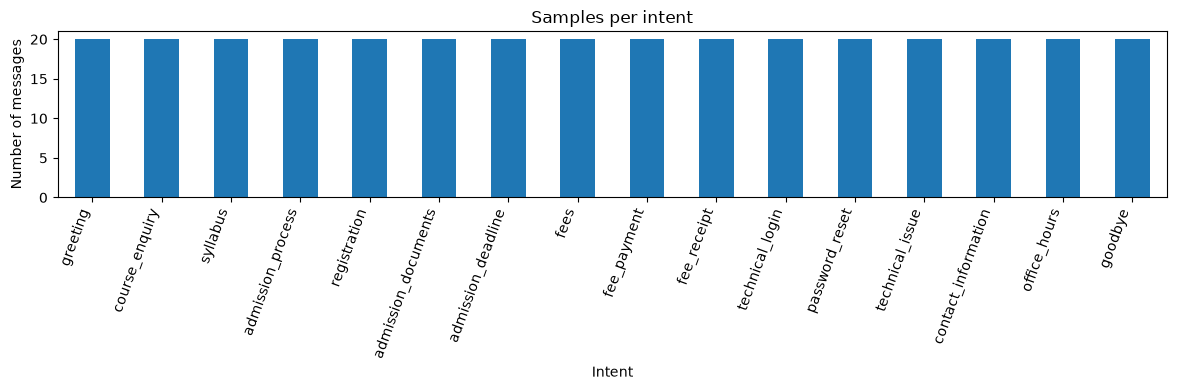

In [3]:
import matplotlib.pyplot as plt

ax = df['intent'].value_counts().plot(kind='bar', figsize=(12, 4), title='Samples per intent')
ax.set_xlabel('Intent')
ax.set_ylabel('Number of messages')
plt.xticks(rotation=70, ha='right')
plt.tight_layout()
plt.show()

## 4. Preprocessing decisions

The training script trims whitespace and removes missing or duplicate records. TF-IDF lowercases text by default, tokenizes it, and creates word and character n-gram features. Negation words are not removed blindly because they may change the intent. Character n-grams can help with minor spelling variation.

## 5. Train and compare two classification models

In [4]:
%run train_model.py

Dataset shape: (320, 2)

Intent distribution:
 intent
admission_deadline     20
admission_documents    20
admission_process      20
contact_information    20
course_enquiry         20
fee_payment            20
fee_receipt            20
fees                   20
goodbye                20
greeting               20
office_hours           20
password_reset         20
registration           20
syllabus               20
technical_issue        20
technical_login        20
Name: count, dtype: int64

Missing values:
 text      0
intent    0
dtype: int64
Duplicate utterances after cleaning: 0

Multinomial Naive Bayes
                     precision    recall  f1-score   support

 admission_deadline       0.71      1.00      0.83         5
admission_documents       1.00      0.80      0.89         5
  admission_process       1.00      1.00      1.00         5
contact_information       1.00      0.60      0.75         5
     course_enquiry       0.80      0.80      0.80         5
        fee_paymen

## 6. Review evaluation results

In [5]:
results_path = Path('reports/model_comparison.csv')
if results_path.exists():
    display(pd.read_csv(results_path))
else:
    print('Run the training cell first.')

errors_path = Path('reports/misclassified_examples.csv')
if errors_path.exists():
    display(pd.read_csv(errors_path).head(30))

,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,Logistic Regression,0.8125,0.832440,0.8125,0.812216,0.812216
1,Multinomial Naive Bayes,0.8125,0.839583,0.8125,0.811174,0.811174


,text,actual_intent,predicted_intent
0,what files must be uploaded with the application,admission_documents,admission_deadline
1,I have a question,greeting,goodbye
2,my student account will not open,technical_login,password_reset
3,when is student services available,office_hours,contact_information
4,give me the admissions office contact,contact_information,office_hours
5,can you help me register,registration,greeting
6,I cannot remember my login password,password_reset,technical_login
7,how can I reach the academic office,contact_information,office_hours
8,I need help with enrollment,registration,greeting
9,stop chatting,goodbye,greeting


## 7. Test an example message

In [6]:
import json, joblib

model = joblib.load('models/smart_faq_pipeline.joblib')
responses = json.loads(Path('models/faq_responses.json').read_text(encoding='utf-8'))

def predict_faq(message, threshold=0.60):
    if not isinstance(message, str) or not message.strip():
        return {'intent': None, 'confidence': 0.0, 'response': 'Please enter a question.'}
    probs = model.predict_proba([message])[0]
    idx = int(probs.argmax())
    intent, confidence = str(model.classes_[idx]), float(probs[idx])
    if confidence < threshold:
        answer = 'I am not confident enough to identify your question. Please rephrase it or contact the relevant office.'
    else:
        answer = responses.get(intent, 'Please contact the relevant office.')
    return {'intent': intent, 'confidence': round(confidence, 3), 'response': answer}

for question in ['How do I apply for admission?', 'How can I get my fee receipt?', 'I forgot my password', 'What is the college phone number?', 'Can you recommend a movie?']:
    print('Question:', question)
    print(predict_faq(question))
    print()

Question: How do I apply for admission?
{'intent': 'admission_process', 'confidence': 0.807, 'response': "A typical admission process is: check the official eligibility criteria, complete the application on the official admissions portal, upload the requested documents, pay any applicable application fee, and track your application status. Follow the institution's official instructions because steps and requirements differ."}

Question: How can I get my fee receipt?
{'intent': 'fee_receipt', 'confidence': 0.902, 'response': "After a successful payment, check the fee portal's Payment History, Transactions, or Receipts section for a downloadable receipt. If it is missing, keep your transaction reference and contact the accounts office to request verification or a duplicate receipt."}

Question: I forgot my password
{'intent': 'password_reset', 'confidence': 0.886, 'response': "Use the official portal's 'Forgot Password' or password recovery option. Check your registered email or phone an

## 8. Launch the Streamlit application

Run from a terminal in the project directory:

```bash
streamlit run app.py
```

The interface includes clickable sample questions, a chat history, predefined responses, prediction details, and a confidence-based fallback.

## 9. Limitations and conclusion

This project implements a complete baseline NLP intent-classification workflow and compares two models on held-out data. The sample dataset is small and custom-created, so evaluation on new, real user queries is necessary. Institution-specific deadlines, fees, office hours, and contact details should be filled in only from verified sources. Intent classification predicts the category of a message; the chatbot then selects a stored response rather than generating a new answer.